In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [2]:
data = pd.read_csv("student_marks.csv")

print("Original Dataset")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

Original Dataset
   Student Name  Total Marks
0  Aarav Sharma           87
1  Ananya Reddy           92
2   Arjun Kumar           76
3    Diya Patel           89
4   Rohan Singh           81

Dataset Shape:
(30, 2)


In [ ]:
# Remove extra spaces from column names
data.columns = data.columns.str.strip()

# Remove extra spaces from student names
data["Student Name"] = data["Student Name"].str.strip()

# Convert Total Marks into numeric format
data["Total Marks"] = pd.to_numeric(
    data["Total Marks"],
    errors="coerce"
)

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Remove missing values
data = data.dropna()

# Remove duplicate records
data = data.drop_duplicates()

# Check for invalid marks
data = data[
    (data["Total Marks"] >= 0) &
    (data["Total Marks"] <= 100)
]

print("\nCleaned Dataset:")
print(data.head())

print("\nCleaned Dataset Shape:")
print(data.shape)


Missing Values:
Student Name    0
Total Marks     0
dtype: int64

Cleaned Dataset:
   Student Name  Total Marks
0  Aarav Sharma           87
1  Ananya Reddy           92
2   Arjun Kumar           76
3    Diya Patel           89
4   Rohan Singh           81

Cleaned Dataset Shape:
(30, 2)


In [4]:
# Student names cannot directly be used by Linear Regression.
# Create a student index for demonstration purposes.

data["Student Index"] = range(1, len(data) + 1)

print("\nDataset after preprocessing:")
print(data.head())



Dataset after preprocessing:
   Student Name  Total Marks  Student Index
0  Aarav Sharma           87              1
1  Ananya Reddy           92              2
2   Arjun Kumar           76              3
3    Diya Patel           89              4
4   Rohan Singh           81              5


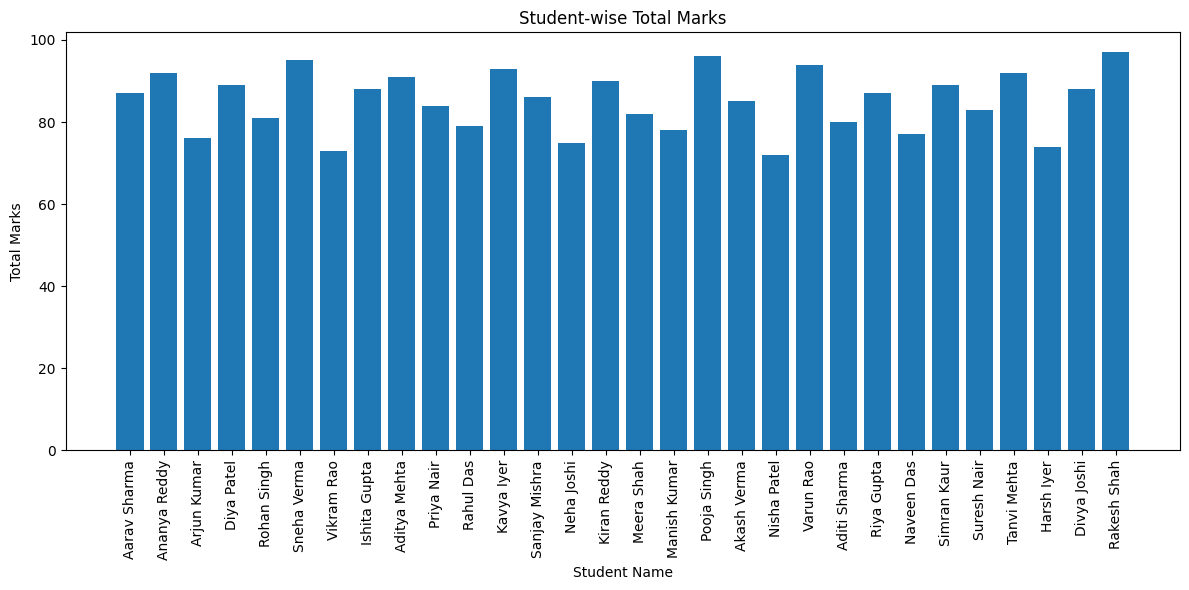

In [5]:
# ------------------------------------------------------------
# Visualization 1: Student-wise Total Marks
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    data["Student Name"],
    data["Total Marks"]
)

plt.xlabel("Student Name")
plt.ylabel("Total Marks")
plt.title("Student-wise Total Marks")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()



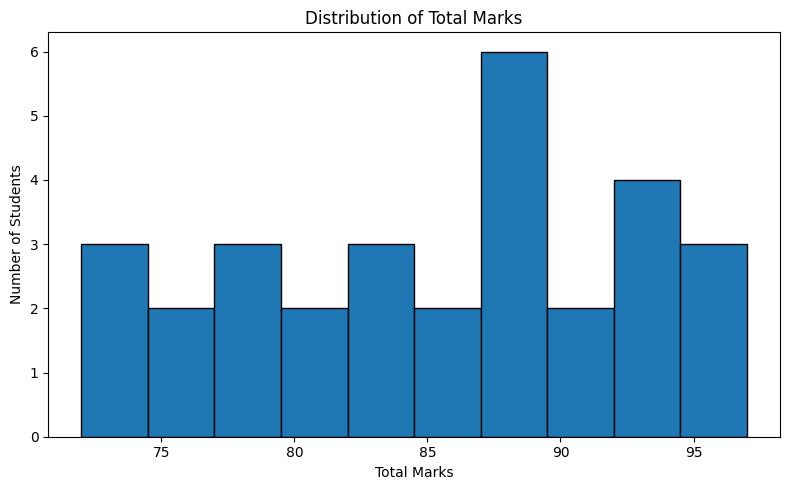

In [6]:
# ------------------------------------------------------------
# Visualization 2: Distribution of Total Marks
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    data["Total Marks"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Total Marks")
plt.ylabel("Number of Students")
plt.title("Distribution of Total Marks")

plt.tight_layout()

plt.show()

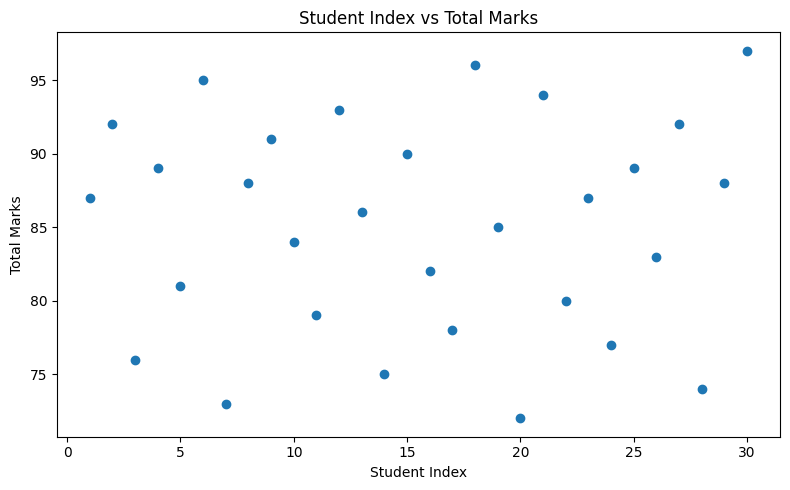

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["Student Index"],
    data["Total Marks"]
)

plt.xlabel("Student Index")
plt.ylabel("Total Marks")
plt.title("Student Index vs Total Marks")

plt.tight_layout()

plt.show()

In [8]:
# ============================================================
# 5. DEFINE X AND Y
# ============================================================

# Independent variable
X = data[["Student Index"]]

# Dependent variable
y = data["Total Marks"]

In [9]:
# ============================================================
# 6. SPLIT DATASET
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)



In [10]:
# ============================================================
# 7. CREATE LINEAR REGRESSION MODEL
# ============================================================

model = LinearRegression()


# ============================================================
# 8. TRAIN MODEL
# ============================================================

model.fit(X_train, y_train)


# ============================================================
# 9. PREDICT
# ============================================================

y_pred = model.predict(X_test)


# ============================================================
# 10. DISPLAY ACTUAL VS PREDICTED
# ============================================================

print("\nActual Marks\tPredicted Marks")

for actual, predicted in zip(y_test, y_pred):

    print(
        actual,
        "\t\t",
        round(predicted, 2)
    )


Actual Marks	Predicted Marks
74 		 87.11
82 		 85.51
77 		 86.58
96 		 85.78
91 		 84.57
84 		 84.71



Mean Squared Error: 70.36
R2 Score: -0.22

Model Coefficient:
0.13340227507755947

Model Intercept:
83.37396587383661


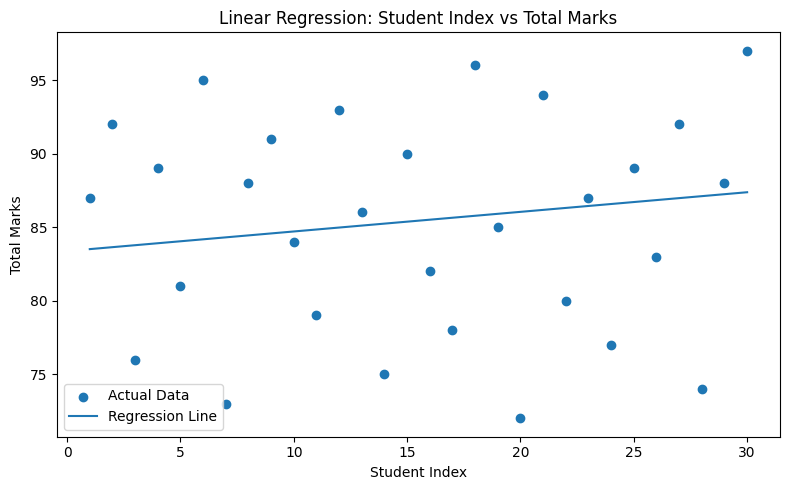

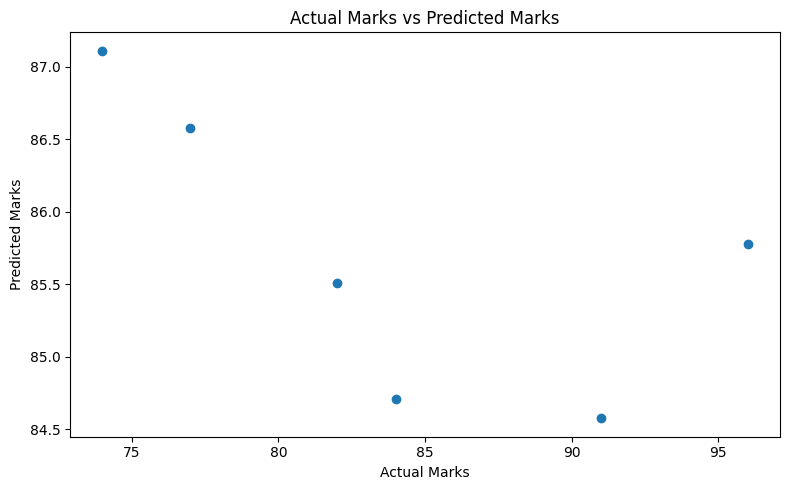

In [11]:
# ============================================================
# 11. MODEL EVALUATION
# ============================================================

mse = mean_squared_error(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\nMean Squared Error:", round(mse, 2))

print("R2 Score:", round(r2, 2))


# ============================================================
# 12. MODEL COEFFICIENT AND INTERCEPT
# ============================================================

print("\nModel Coefficient:")
print(model.coef_[0])

print("\nModel Intercept:")
print(model.intercept_)


# ============================================================
# 13. REGRESSION LINE VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    X,
    y,
    label="Actual Data"
)

plt.plot(
    X,
    model.predict(X),
    label="Regression Line"
)

plt.xlabel("Student Index")
plt.ylabel("Total Marks")

plt.title(
    "Linear Regression: Student Index vs Total Marks"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. ACTUAL VS PREDICTED MARKS
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.title(
    "Actual Marks vs Predicted Marks"
)

plt.tight_layout()

plt.show()